# Salary Prediction with Simple Linear Regression

**Author:** Faith Njah

Can years of experience predict salary? This notebook builds, evaluates and saves a simple linear regression model, then uses it to make predictions.

**Dataset:** [Salary Dataset: Simple Linear Regression (Kaggle)](https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression): 30 employees, each with years of experience and annual salary.

**Steps**
1. Load and explore the data
2. Visualise the relationship
3. Evaluate the model with cross-validation
4. Train the final model
5. Check the residuals
6. Make predictions
7. Save the model
8. Summary and limitations

## 1. Load and explore the data

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv("../data/salary_data.csv")
print(f"{df.shape[0]} rows x {df.shape[1]} columns")
df.head()

30 rows x 2 columns


,YearsExperience,Salary
0,1.2,39344
1,1.4,46206
2,1.6,37732
3,2.1,43526
4,2.3,39892


In [2]:
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", df.duplicated().sum())
df.describe().round(2)

Missing values: 0
Duplicate rows: 0


,YearsExperience,Salary
count,30.00,30.00
mean,5.41,76004.00
std,2.84,27414.43
min,1.20,37732.00
25%,3.30,56721.75
50%,4.80,65238.00
75%,7.80,100545.75
max,10.60,122392.00


**Observation:** the data is clean, with no missing values or duplicates. Experience ranges from 1.2 to 10.6 years and salary from about 37,700 to 122,400.

## 2. Visualise the relationship

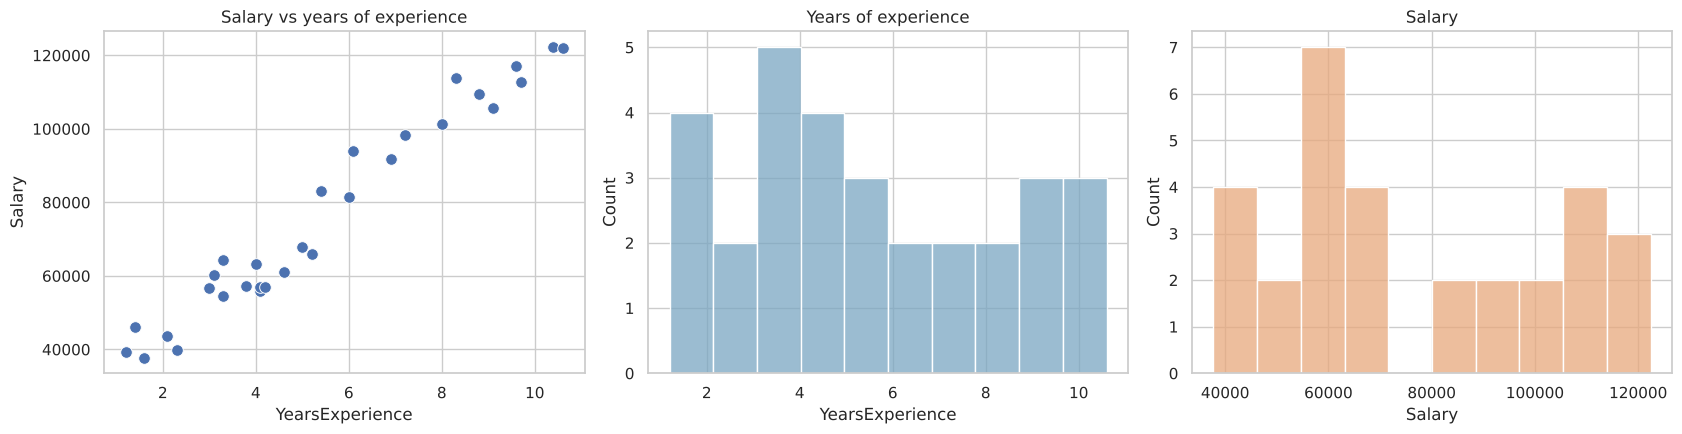

Correlation: 0.978


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="YearsExperience", y="Salary", s=70, ax=axes[0], color="#4c72b0")
axes[0].set_title("Salary vs years of experience")
sns.histplot(df["YearsExperience"], bins=10, ax=axes[1], color="#7aa6c2")
axes[1].set_title("Years of experience")
sns.histplot(df["Salary"], bins=10, ax=axes[2], color="#e8a87c")
axes[2].set_title("Salary")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda.png", dpi=120)
plt.show()

print(f"Correlation: {df['YearsExperience'].corr(df['Salary']):.3f}")

**Observation:** the points lie close to a straight line, with a correlation of about 0.98. That makes a linear model a reasonable choice.

## 3. Evaluate the model with cross-validation
With only 30 rows, one 80/20 split would test on just 6 people, and the score would depend heavily on which 6 were picked. **5-fold cross-validation** is more reliable: every employee is predicted exactly once by a model that never saw them during training.

In [4]:
X = df[["YearsExperience"]]
y = df["Salary"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_pred = cross_val_predict(LinearRegression(), X, y, cv=cv)

r2 = r2_score(y, cv_pred)
mae = mean_absolute_error(y, cv_pred)
rmse = np.sqrt(mean_squared_error(y, cv_pred))
print(f"R²   {r2:.3f}")
print(f"MAE  {mae:,.0f}")
print(f"RMSE {rmse:,.0f}")

R²   0.954
MAE  4,727
RMSE 5,812


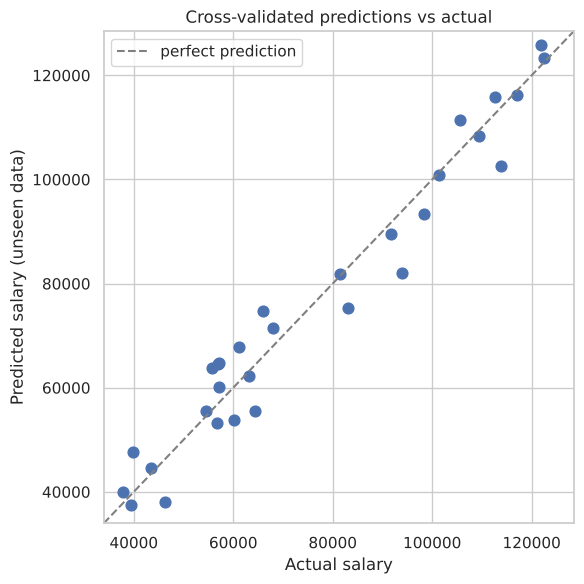

In [5]:
plt.figure(figsize=(6, 6))
plt.scatter(y, cv_pred, s=60, color="#4c72b0")
lims = [y.min() * 0.9, y.max() * 1.05]
plt.plot(lims, lims, "--", color="gray", label="perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual salary")
plt.ylabel("Predicted salary (unseen data)")
plt.title("Cross-validated predictions vs actual")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "actual_vs_predicted.png", dpi=120)
plt.show()

**Observation:** on employees it hasn't seen, the model explains about 95% of the variation in salary (R² of about 0.95 across all out-of-fold predictions), and its predictions are typically off by about 4,700.

## 4. Train the final model
Cross-validation estimated how well the approach generalises. The final model is trained on **all 30 rows**, so it learns from every data point.

In [6]:
model = LinearRegression().fit(X, y)
print(f"Intercept: {model.intercept_:,.2f}")
print(f"Slope:     {model.coef_[0]:,.2f}")
print(f"\nSalary = {model.intercept_:,.0f} + {model.coef_[0]:,.0f} x YearsExperience")

Intercept: 24,848.20
Slope:     9,449.96

Salary = 24,848 + 9,450 x YearsExperience


**Interpretation**
- **Slope:** each additional year of experience is associated with about **9,450 more** in salary.
- **Intercept:** the model's estimate for zero experience is about 24,850. No one in the data has less than 1.2 years of experience, so treat this as where the line starts, not a real starting salary.

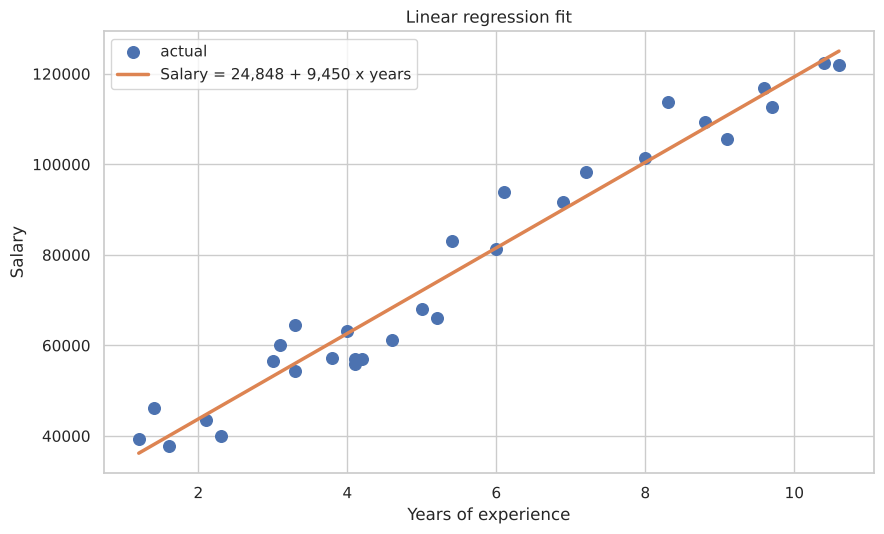

In [7]:
x_line = np.linspace(df["YearsExperience"].min(), df["YearsExperience"].max(), 100)
y_line = model.predict(pd.DataFrame({"YearsExperience": x_line}))

plt.figure(figsize=(9, 5.5))
plt.scatter(df["YearsExperience"], df["Salary"], s=70, color="#4c72b0", label="actual")
plt.plot(x_line, y_line, color="#dd8452", linewidth=2.5,
         label=f"Salary = {model.intercept_:,.0f} + {model.coef_[0]:,.0f} x years")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.title("Linear regression fit")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "regression_line.png", dpi=120)
plt.show()

## 5. Check the residuals
A residual is the actual salary minus the predicted one. If a straight line is the right model, the residuals should scatter randomly around zero with no pattern.

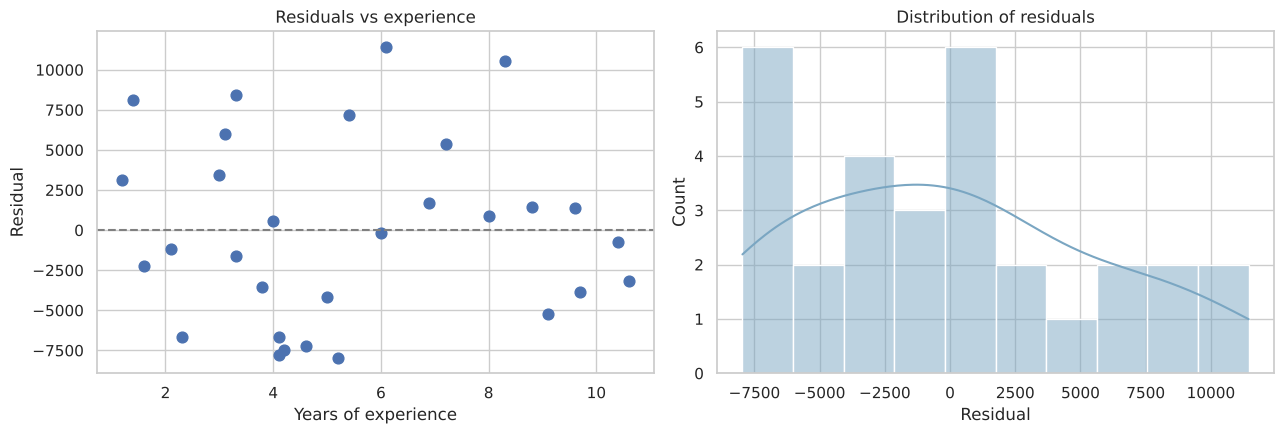

Training R²: 0.957


In [8]:
residuals = y - model.predict(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df["YearsExperience"], residuals, s=60, color="#4c72b0")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_xlabel("Years of experience")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs experience")
sns.histplot(residuals, bins=10, kde=True, ax=axes[1], color="#7aa6c2")
axes[1].set_title("Distribution of residuals")
axes[1].set_xlabel("Residual")
fig.tight_layout()
fig.savefig(FIG_DIR / "residuals.png", dpi=120)
plt.show()

print(f"Training R²: {r2_score(y, model.predict(X)):.3f}")

**Observation:** the residuals scatter around zero without a clear curve or funnel shape, so a straight line fits this data well. The training R² is only slightly higher than the cross-validated score, which suggests the model isn't overfitting.

## 6. Make predictions

In [9]:
new = pd.DataFrame({"YearsExperience": [1.5, 3, 5, 7.5, 10]})
new["PredictedSalary"] = model.predict(new).round(0)
new

,YearsExperience,PredictedSalary
0,1.5,39023.0
1,3.0,53198.0
2,5.0,72098.0
3,7.5,95723.0
4,10.0,119348.0


Predictions are most trustworthy **within 1.2–10.6 years**, the range the model was trained on. Beyond that, the straight line assumes salaries keep rising at the same rate forever, which real careers don't do.

## 7. Save the model

In [10]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(model, "../models/salary_model.joblib")

reloaded = joblib.load("../models/salary_model.joblib")
print("Reloaded model prediction for 5 years:",
      f"{reloaded.predict(pd.DataFrame({'YearsExperience': [5]}))[0]:,.0f}")

Reloaded model prediction for 5 years: 72,098


## 8. Summary and limitations

| | |
|---|---|
| Model | Simple linear regression (scikit-learn) |
| Equation | Salary ≈ 24,848 + 9,450 × years of experience |
| Cross-validated R² | ≈ 0.95 |
| Cross-validated MAE | ≈ 4,700 |

**Limitations**
- **Small sample:** 30 employees isn't much, so the estimates come with real uncertainty.
- **One feature:** salary also depends on role, location, education and industry, none of which the model sees.
- **Extrapolation:** predictions outside 1.2–10.6 years assume a straight-line trend continues.

**Possible next steps:** add more features (multiple regression), collect more data, or try models that allow salary growth to level off.